# 04 - Visualization Best Practices
This notebook shows **bad vs good** examples side by side.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(3)

## 1. Choose the right chart type

| Question | Chart |
|---|---|
| Trend over time | Line |
| Compare categories | Bar (horizontal if long names) |
| Relationship of 2 numbers | Scatter |
| Distribution | Histogram, box, violin |
| Parts of a whole (2-5 parts) | Pie / donut / stacked bar |
| Correlations | Heatmap |
| Hierarchy | Treemap |

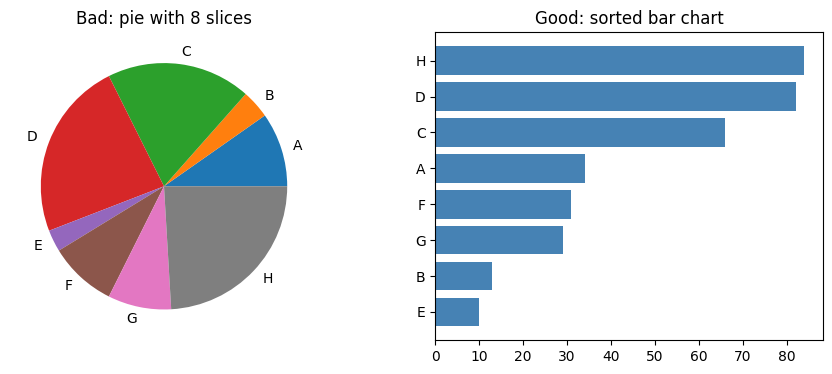

In [2]:
cats = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']
vals = np.random.randint(10, 100, 8)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].pie(vals, labels=cats)
ax[0].set_title('Bad: pie with 8 slices')

order = np.argsort(vals)
ax[1].barh(np.array(cats)[order], vals[order], color='steelblue')
ax[1].set_title('Good: sorted bar chart')
plt.show()

## 2. Avoid misleading visuals
### a) Truncated y-axis

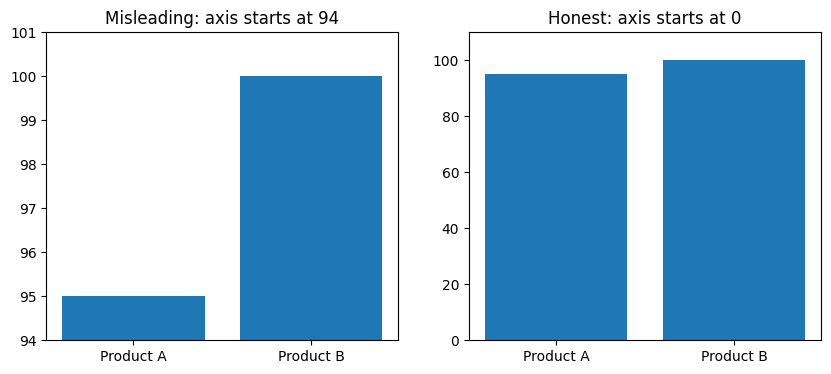

In [3]:
labels = ['Product A', 'Product B']
values = [95, 100]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(labels, values)
ax[0].set_ylim(94, 101)
ax[0].set_title('Misleading: axis starts at 94')

ax[1].bar(labels, values)
ax[1].set_ylim(0, 110)
ax[1].set_title('Honest: axis starts at 0')
plt.show()

### b) Too many colors vs one highlight color
Use grey for context and one strong color for your message.

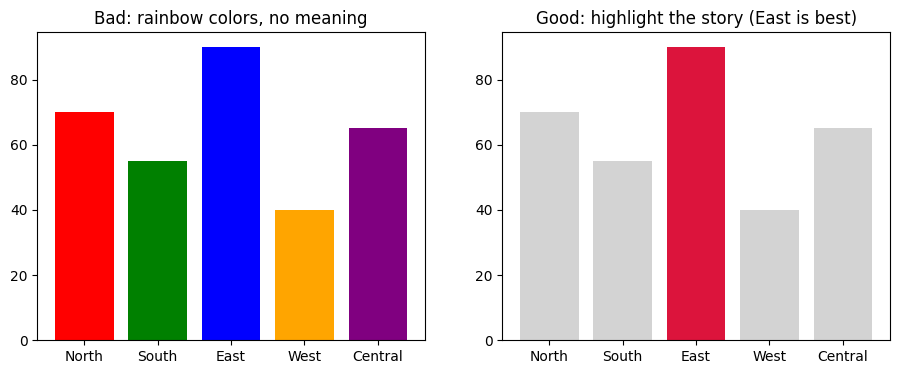

In [4]:
regions = ['North', 'South', 'East', 'West', 'Central']
sales = [70, 55, 90, 40, 65]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(regions, sales, color=['red', 'green', 'blue', 'orange', 'purple'])
ax[0].set_title('Bad: rainbow colors, no meaning')

ax[1].bar(regions, sales, color=['lightgrey', 'lightgrey', 'crimson', 'lightgrey', 'lightgrey'])
ax[1].set_title('Good: highlight the story (East is best)')
plt.show()

## 3. Color selection
- **Sequential** palette (light to dark) for numbers: `Blues`, `viridis`
- **Diverging** palette for values around a middle point: `coolwarm`, `RdBu`
- **Categorical** palette for groups: `Set2`, `tab10`
- Use color-blind-friendly palettes: `sns.color_palette('colorblind')`

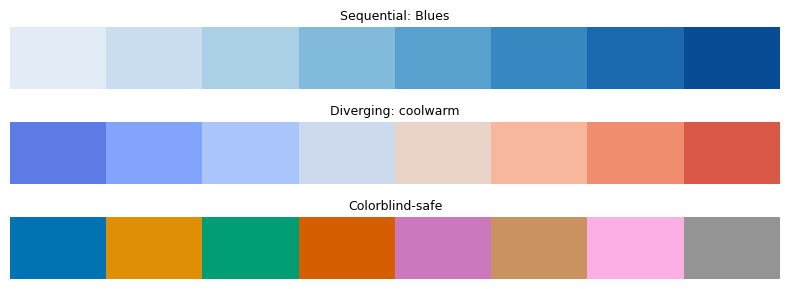

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(8, 3))
for a, (name, pal) in zip(ax, [('Sequential: Blues', sns.color_palette('Blues', 8)),
                              ('Diverging: coolwarm', sns.color_palette('coolwarm', 8)),
                              ('Colorblind-safe', sns.color_palette('colorblind', 8))]):
    a.imshow([list(range(8))], cmap=plt.matplotlib.colors.ListedColormap(pal), aspect='auto')
    a.set_title(name, fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.show()

## 4. Clear labeling
A good chart has: a **title that states the message**, labeled axes **with units**, a legend only if needed, and a source note.

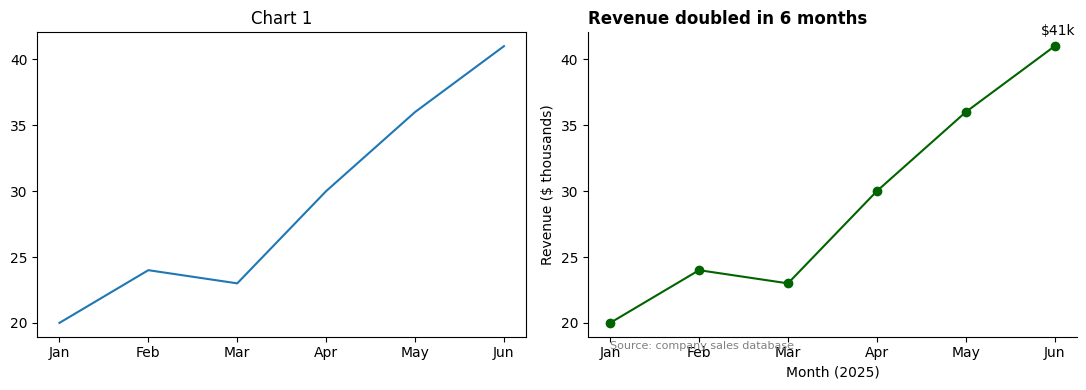

In [6]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']
rev = [20, 24, 23, 30, 36, 41]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(months, rev)
ax[0].set_title('Chart 1')

ax[1].plot(months, rev, marker='o', color='darkgreen')
ax[1].set_title('Revenue doubled in 6 months', loc='left', fontweight='bold')
ax[1].set_xlabel('Month (2025)')
ax[1].set_ylabel('Revenue ($ thousands)')
ax[1].annotate('$41k', (5, 41), textcoords='offset points', xytext=(-10, 8))
ax[1].spines[['top', 'right']].set_visible(False)
ax[1].text(0, 18, 'Source: company sales database', fontsize=8, color='grey')
plt.tight_layout()
plt.show()

## 5. Reduce clutter
Remove what does not help: heavy gridlines, 3D effects, extra borders.

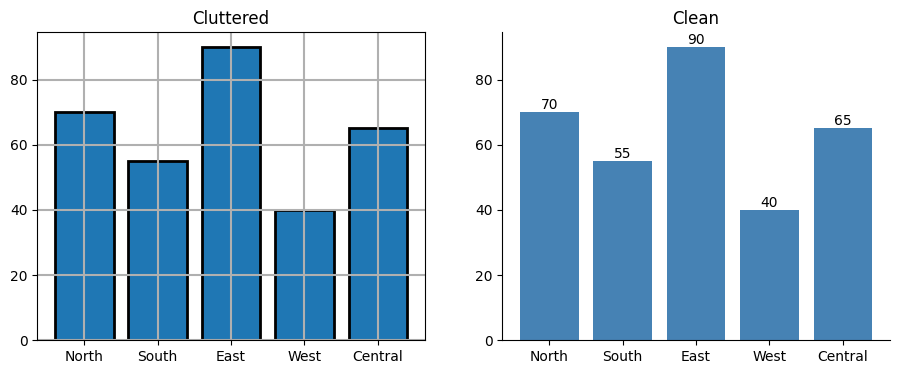

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(regions, sales, edgecolor='black', linewidth=2)
ax[0].grid(True, linewidth=1.5)
ax[0].set_title('Cluttered')

ax[1].bar(regions, sales, color='steelblue')
ax[1].spines[['top', 'right']].set_visible(False)
ax[1].set_title('Clean')
for i, v in enumerate(sales):
    ax[1].text(i, v + 1, v, ha='center')
plt.show()

## Checklist
- [ ] Right chart type?
- [ ] Title says the message?
- [ ] Axes labeled with units?
- [ ] Bar charts start at zero?
- [ ] Few colors, with meaning?
- [ ] Color-blind friendly?
- [ ] No clutter?